# M3 — toy asset–liability example

Not a pension fund model: one fixed liability schedule, a few zero-coupon bonds, revalued on each simulated curve. Scope decisions are in `LOG.md`.

## Assumptions (liability schedule)
- **Payments:** 1 per year at t = 1, 2, ..., 30 years from today (flat, deterministic). No members, mortality, inflation or contributions.
- **Horizon:** the 250 simulated business days are treated as 1 year.
- **At the horizon:** the t = 1 payment falls due and is paid out of assets, so it drops from both sides. The remaining liabilities are payments at 1, 2, ..., 29 years from then, so no extrapolation beyond the 30Y curve point is needed.
- **Discounting:** on the simulated curve at the horizon, linear interpolation across the six maturities (1Y, 2Y, 5Y, 10Y, 20Y, 30Y), flat extrapolation below 1Y. Annual compounding, `DF(t) = (1 + y(t)/100) ** -t`, yields in percent.
- **Initial funding ratio:** 1.0 by construction, assets sized to the present value of the liabilities on today's curve.

In [1]:
import matplotlib.pyplot as plt
plt.style.use("default"); plt.rcParams["figure.facecolor"] = "white"  # undo IDE dark-theme recolouring

PAYMENT = 1.0
PAY_TIMES = list(range(1, 31))       # years from today
HORIZON_YEARS = 1                    # 250 business days
REMAINING_TIMES = [t - HORIZON_YEARS for t in PAY_TIMES if t > HORIZON_YEARS]   # 1..29 at the horizon

## Today's liability value and duration

Interpolate today's curve at each payment date, discount, and compute the PV and the Macaulay duration (PV-weighted average payment time).

In [2]:
import numpy as np
from scenario_lab.data import load_curve

levels = load_curve("AAA")
MATS = np.array([1, 2, 5, 10, 20, 30.])      # curve maturities in years
y_now = levels.iloc[-1].values               # today's curve, percent

def discount_factors(y, times):
    """y: yields (percent) at MATS; times: payment times in years. Linear interpolation, annual compounding."""
    return (1 + np.interp(times, MATS, y) / 100) ** -np.asarray(times)

t = np.array(PAY_TIMES)
df = discount_factors(y_now, t)
pv_liab = PAYMENT * df.sum()
dur_liab = (t * df).sum() / df.sum()
print(f"liability PV = {pv_liab:.2f}, duration = {dur_liab:.2f} years")

liability PV = 18.18, duration = 12.76 years


## Asset portfolios (static, buy-and-hold)

Zero-coupon bonds at 5Y and 30Y, weights as shares of the initial asset value (= liability PV, so the initial funding ratio is 1). A zero-coupon bond's duration equals its maturity, so the matched mix solves `w5 * 5 + w30 * 30 = duration`.

In [3]:
w30 = (dur_liab - 5) / (30 - 5)
PORTFOLIOS = {
    "Short":   {5: 1.0, 30: 0.0},
    "Matched": {5: 1 - w30, 30: w30},
    "Long":    {5: 0.0, 30: 1.0},
}
for name, w in PORTFOLIOS.items():
    print(f"{name:8s} 5Y {w[5]:.1%}  30Y {w[30]:.1%}  duration {5 * w[5] + 30 * w[30]:.2f}")

Short    5Y 100.0%  30Y 0.0%  duration 5.00
Matched  5Y 68.9%  30Y 31.1%  duration 12.76
Long     5Y 0.0%  30Y 100.0%  duration 30.00


## Horizon revaluation

For each simulated path at day 250, for one portfolio:
1. **Bonds.** A zero of maturity T bought today at `DF_today(T)` has face = `w * pv_liab / DF_today(T)`. At the horizon it has remaining maturity `T - 1`, worth `face * DF_h(T - 1)` on the simulated curve.
2. **Payment due.** The t = 1 liability payment is paid from assets: `assets_h = sum of bond values - PAYMENT`.
3. **Liabilities.** `liabilities_h = PAYMENT * sum(DF_h(REMAINING_TIMES))` on the same simulated curve.
4. **Funding ratio** = `assets_h / liabilities_h`, one value per path, shape `(n_paths,)`.

`DF_today` uses today's curve (the purchase price fixes the face value), `DF_h` uses the path's day-250 curve.

In [4]:
from scenario_lab import model as m

p_all = m.fit(levels.diff().dropna())
curves = m.simulate(p_all, y_now)          # (paths, 251, 6)
y_h = curves[:, -1]                        # curves at the horizon, (paths, 6)


In [5]:
def funding_ratio(y_h, weights):
    """y_h: (n_paths, 6) simulated curves at the horizon; weights: {maturity: w} from PORTFOLIOS.
    Returns the funding ratio per path, shape (n_paths,)."""
    # face values are fixed at purchase (today's curve), so compute them once
    face = {T: w * pv_liab / discount_factors(y_now, T) for T, w in weights.items()}
    funding_ratios = np.zeros(y_h.shape[0])
    for j, y in enumerate(y_h):
        assets = sum(face[T] * discount_factors(y, T - 1) for T in weights) - PAYMENT
        liabilities = PAYMENT * discount_factors(y, REMAINING_TIMES).sum()
        funding_ratios[j] = assets / liabilities
    return funding_ratios

In [6]:
fr = {name: funding_ratio(y_h, w) for name, w in PORTFOLIOS.items()}

## Sanity checks

Feed `funding_ratio` deterministic curves instead of simulated ones:
- **Today's curve:** every portfolio should be close to 1 (small deviation from one year of roll-down and the paid-out payment).
- **Parallel shift +1pp / -1pp:** Long should fall below Matched and Short rise above it after +1pp, and the reverse after -1pp. Matched should barely move.

In [7]:
# Sanity checks: one deterministic curve per case, so one funding ratio per portfolio
for label, y_test in {"today": y_now, "+1pp": y_now + 1, "-1pp": y_now - 1}.items():
    Y = np.tile(y_test, (2, 1))      # funding_ratio needs (n_paths, 6)
    print(f"{label:6s}", {name: round(funding_ratio(Y, w)[0], 3) for name, w in PORTFOLIOS.items()})

today  {'Short': np.float64(0.996), 'Matched': np.float64(0.997), 'Long': np.float64(0.999)}
+1pp   {'Short': np.float64(1.075), 'Matched': np.float64(1.0), 'Long': np.float64(0.835)}
-1pp   {'Short': np.float64(0.917), 'Matched': np.float64(1.001), 'Long': np.float64(1.186)}


## Results

Per portfolio: mean and spread of the funding ratio, the probability of ending below 1, and the tail risk. **VaR95** is the 5th percentile of the funding ratio, **ES95** the average funding ratio in the worst 5% of paths (lower is worse). The plot shows the smoothed distribution of the funding ratio at day 250 (density; the area under each curve is 1).

Short    mean 0.996  std 0.062  P(FR<1) 52.3%  VaR95 0.895  ES95 0.869
Matched  mean 1.000  std 0.014  P(FR<1) 52.3%  VaR95 0.978  ES95 0.972
Long     mean 1.008  std 0.152  P(FR<1) 50.1%  VaR95 0.772  ES95 0.724


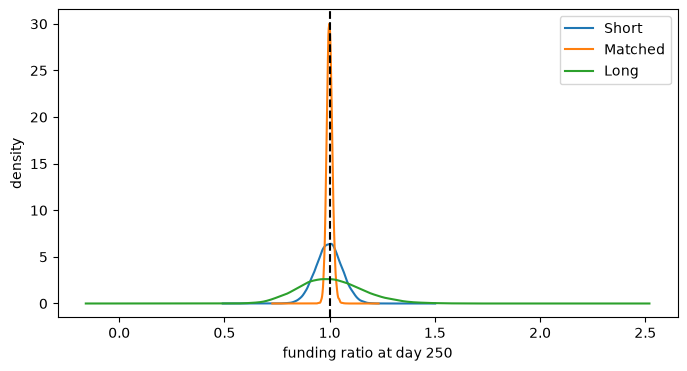

In [8]:
import pandas as pd

# 1. Summary table: one row per portfolio
for name, x in fr.items():
    var = np.percentile(x, 5)        # VaR 95%: FR level that is only undercut in 5% of paths
    es = x[x <= var].mean()          # expected shortfall: average FR in that worst 5%
    print(f"{name:8s} mean {x.mean():.3f}  std {x.std():.3f}  P(FR<1) {(x < 1).mean():.1%}  VaR95 {var:.3f}  ES95 {es:.3f}")

# 2. Distribution of the funding ratio per portfolio
fig, ax = plt.subplots(figsize=(8, 4))
for name, x in fr.items():
    pd.Series(x).plot.kde(ax=ax, label=name)      # smooth density curve
ax.axvline(1, color="k", ls="--")          # FR = 1: fully funded
ax.set_xlabel("funding ratio at day 250")      
ax.set_ylabel("density")
ax.legend()
plt.show()